# 02 — Wavelet decomposition

Each series is split into a **trend** and a **seasonal** component by multiresolution
analysis (MRA) with the discrete Meyer wavelet, at the series' native cadence, then
aggregated to monthly.

**Why decompose.** NDVI in the orchard mixes two processes on different time scales: the
annual cycle of the herbaceous layer and the canopy (97% of the variance, below), and slow
changes over several years, such as drought legacies or management. Separating them lets a
model, and its explanation, address each process on its own scale (Martínez and Gilabert,
2009; Ben Abbes et al., 2018).

**Why MRA, and why the Meyer wavelet.** MRA splits a series into components that add back
exactly to the original (Mallat, 1989; Percival and Walden, 2000), so forecasts of the
components can be summed into a forecast of NDVI. The Meyer wavelet has a compactly
supported, smooth frequency response, so the split between "slower than a year" and
"faster than a year" is sharper than with short wavelets such as Haar or low-order
Daubechies. `dmey` in PyWavelets is its finite (62-tap) approximation (Lee et al., 2019).

**Why one year.** The cut between trend and seasonal is set at the annual cycle, the
dominant period of Mediterranean vegetation, so the trend holds only what is slower than
one growing season.

The decomposition is two-sided: a component at month *t* uses later months. This is
measured below (Look-ahead), and a strictly causal alternative is built for notebook 09.

Input: `data/raw/` · Output: `data/processed/orchard_decomposed.csv`

In [1]:
import warnings

import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Expected at these levels and explained under "Boundary handling" below; silenced
# so the diagnostic output stays readable.
warnings.filterwarnings("ignore", message="Level value of .* is too high")

master = pd.read_csv("../data/raw/orchard_monthly.csv",
                     index_col="date", parse_dates=True)

ndvi16 = (pd.read_csv("../data/raw/orchard_ndvi_16day.csv", parse_dates=["date"])
            .set_index("date")["NDVI"])
lst8 = (pd.read_csv("../data/raw/orchard_lst_8day.csv", parse_dates=["date"])
          .set_index("date")["LST"])

SPEI_COLS = ["SPEI_1", "SPEI_3", "SPEI_6", "SPEI_12", "SPEI_24", "SPEI_48"]
ALL_SERIES = ["NDVI", "LST"] + SPEI_COLS

print(f"monthly {master.shape}   16-day NDVI {len(ndvi16)}   8-day LST {len(lst8)}")
print(f"NDVI composites masked as cloud: {ndvi16.isna().sum()} of {len(ndvi16)} -> interpolated")
print(f"LST composites withheld by MODIS: {lst8.isna().sum()} of {len(lst8)} -> interpolated")
ndvi16 = ndvi16.interpolate()
lst8 = lst8.interpolate()

monthly (298, 10)   16-day NDVI 571   8-day LST 1141
NDVI composites masked as cloud: 18 of 571 -> interpolated
LST composites withheld by MODIS: 8 of 1141 -> interpolated


## Levels

At level *J*, the approximation keeps periods longer than about twice the semi-period
`p = 2^J · Δt / (2 · v_c)`, where Δt is the sampling interval and `v_c` the wavelet's
centre frequency (Percival and Walden, 2000). The level is the one whose semi-period falls
nearest one year: 5 for 16-day NDVI, 6 for 8-day LST and 4 for monthly SPEI. Decomposing
at the native cadence, before monthly aggregation, keeps the full temporal resolution of
the products for the filter.

In [2]:
WAVELET = "dmey"
V_C = pywt.central_frequency(WAVELET)
CADENCE = {"NDVI": 16.0, "LST": 8.0, "SPEI": 365.25 / 12}
TARGET_DAYS = 365.25


def semi_period(level, dt):
    return 2 ** level * dt / (2 * V_C)


LEVELS = {k: min(range(2, 9), key=lambda j: abs(semi_period(j, dt) - TARGET_DAYS))
          for k, dt in CADENCE.items()}

print(f"{WAVELET}: centre frequency {V_C:.4f}, filter length "
      f"{pywt.Wavelet(WAVELET).dec_len}\n")
print(f"{'index':6s} {'dt (d)':>7s} {'level':>6s} {'scale':>6s} "
      f"{'semi-period':>12s}   neighbours")
for k, dt in CADENCE.items():
    j = LEVELS[k]
    print(f"{k:6s} {dt:7.2f} {j:6d} {2**j:6d} {semi_period(j, dt):10.0f} d   "
          f"level {j-1} -> {semi_period(j-1, dt):.0f} d, "
          f"level {j+1} -> {semi_period(j+1, dt):.0f} d")

assert LEVELS == {"NDVI": 5, "LST": 6, "SPEI": 4}, LEVELS

dmey: centre frequency 0.6721, filter length 62

index   dt (d)  level  scale  semi-period   neighbours
NDVI     16.00      5     32        381 d   level 4 -> 190 d, level 6 -> 762 d
LST       8.00      6     64        381 d   level 5 -> 190 d, level 7 -> 762 d
SPEI     30.44      4     16        362 d   level 3 -> 181 d, level 5 -> 725 d


## Decomposition

A finite series has edges, and the filter needs values beyond them. The series is mirrored
at both ends before decomposing (symmetric extension; Percival and Walden, 2000; Ben Abbes
et al., 2018), which avoids the jump that zero-padding would create. The trend is the
approximation `A_J`; the seasonal component is the series minus the trend, so trend +
seasonal reproduces the series exactly. Cloud-masked NDVI and missing LST composites are
linearly interpolated first, since the transform needs an evenly sampled series.

In [3]:
def decompose(series, level, pad_frac=0.5):
    """MRA at the series' own cadence, with the series mirrored at both ends."""
    x = series.to_numpy(float)
    n = len(x)
    p = int(pad_frac * n)
    xp = np.concatenate([x[:p][::-1], x, x[-p:][::-1]])

    comps = [c[p:p + n] for c in
             pywt.mra(xp, WAVELET, level=level, transform="dwt", mode="symmetric")]

    trend = pd.Series(comps[0], index=series.index)
    finest = pd.Series(comps[-1], index=series.index)
    return trend, series - trend, finest


decomp = master.copy()
finest_share = {}

for name, series in [("NDVI", ndvi16), ("LST", lst8)]:          # native cadence
    trend, seasonal, d1 = decompose(series, LEVELS[name])
    decomp[name] = series.resample("MS").mean()   # gap-filled, so T + S = series
    decomp[f"{name}_T"] = trend.resample("MS").mean()
    decomp[f"{name}_S"] = seasonal.resample("MS").mean()
    finest_share[name] = d1.std() / series.std()

for col in SPEI_COLS:                                           # already monthly
    trend, seasonal, d1 = decompose(master[col], LEVELS["SPEI"])
    decomp[f"{col}_T"], decomp[f"{col}_S"] = trend, seasonal
    finest_share[col] = d1.std() / master[col].std()

for col in ALL_SERIES:
    src = {"NDVI": ndvi16, "LST": lst8}.get(col, master[col])
    lvl = LEVELS[col] if col in LEVELS else LEVELS["SPEI"]
    print(f"{col:8s} n={len(src):5d}  level {lvl}  "
          f"trend sd {decomp[f'{col}_T'].std():7.4f}  "
          f"seasonal sd {decomp[f'{col}_S'].std():8.4f}  "
          f"D1 {finest_share[col]:5.1%} of series sd")

print(f"\n{decomp.shape}")

NDVI     n=  571  level 5  trend sd  0.0280  seasonal sd   0.1651  D1 10.0% of series sd
LST      n= 1141  level 6  trend sd  1.0128  seasonal sd  11.2318  D1 13.8% of series sd
SPEI_1   n=  298  level 4  trend sd  0.3111  seasonal sd   1.0007  D1 65.3% of series sd
SPEI_3   n=  298  level 4  trend sd  0.5231  seasonal sd   0.9062  D1 31.2% of series sd
SPEI_6   n=  298  level 4  trend sd  0.7361  seasonal sd   0.7548  D1 26.6% of series sd
SPEI_12  n=  298  level 4  trend sd  0.9224  seasonal sd   0.5980  D1 14.9% of series sd
SPEI_24  n=  298  level 4  trend sd  1.0629  seasonal sd   0.2707  D1 10.0% of series sd
SPEI_48  n=  298  level 4  trend sd  1.0178  seasonal sd   0.2349  D1  7.3% of series sd

(298, 26)


## Verification

In [4]:
print("exact reconstruction, max |T + S - series|:")
for col in ALL_SERIES:
    err = (decomp[f"{col}_T"] + decomp[f"{col}_S"] - decomp[col]).abs().max()
    print(f"  {col:8s} {err:.2e}")

print(f"\n{'series':8s} {'trend':>8s} {'seasonal':>9s} {'D1 share':>9s}")
for col in ALL_SERIES:
    vt, vs = decomp[f"{col}_T"].var(), decomp[f"{col}_S"].var()
    print(f"{col:8s} {vt / (vt + vs):7.1%} {vs / (vt + vs):8.1%} "
          f"{finest_share[col]:8.1%}")

print("\nSPEI climatology by calendar month "
      "(flat if SPEI is standardised per month, as documented):")
print(master.groupby(master.index.month)[SPEI_COLS].mean().round(2).to_string())

exact reconstruction, max |T + S - series|:
  NDVI     1.11e-16
  LST      7.11e-15
  SPEI_1   2.22e-16
  SPEI_3   2.22e-16
  SPEI_6   2.22e-16
  SPEI_12  5.55e-17
  SPEI_24  1.11e-16
  SPEI_48  5.55e-17

series      trend  seasonal  D1 share
NDVI        2.8%    97.2%    10.0%
LST         0.8%    99.2%    13.8%
SPEI_1      8.8%    91.2%    65.3%
SPEI_3     25.0%    75.0%    31.2%
SPEI_6     48.7%    51.3%    26.6%
SPEI_12    70.4%    29.6%    14.9%
SPEI_24    93.9%     6.1%    10.0%
SPEI_48    94.9%     5.1%     7.3%

SPEI climatology by calendar month (flat if SPEI is standardised per month, as documented):
      SPEI_1  SPEI_3  SPEI_6  SPEI_12  SPEI_24  SPEI_48
date                                                   
1      -0.23   -0.21   -0.25    -0.46    -0.65    -0.84
2      -0.19   -0.26   -0.26    -0.42    -0.62    -0.79
3      -0.09   -0.29   -0.29    -0.48    -0.63    -0.76
4      -0.22   -0.26   -0.33    -0.48    -0.63    -0.78
5      -0.18   -0.21   -0.40    -0.49    -0.63  

## Decomposed series

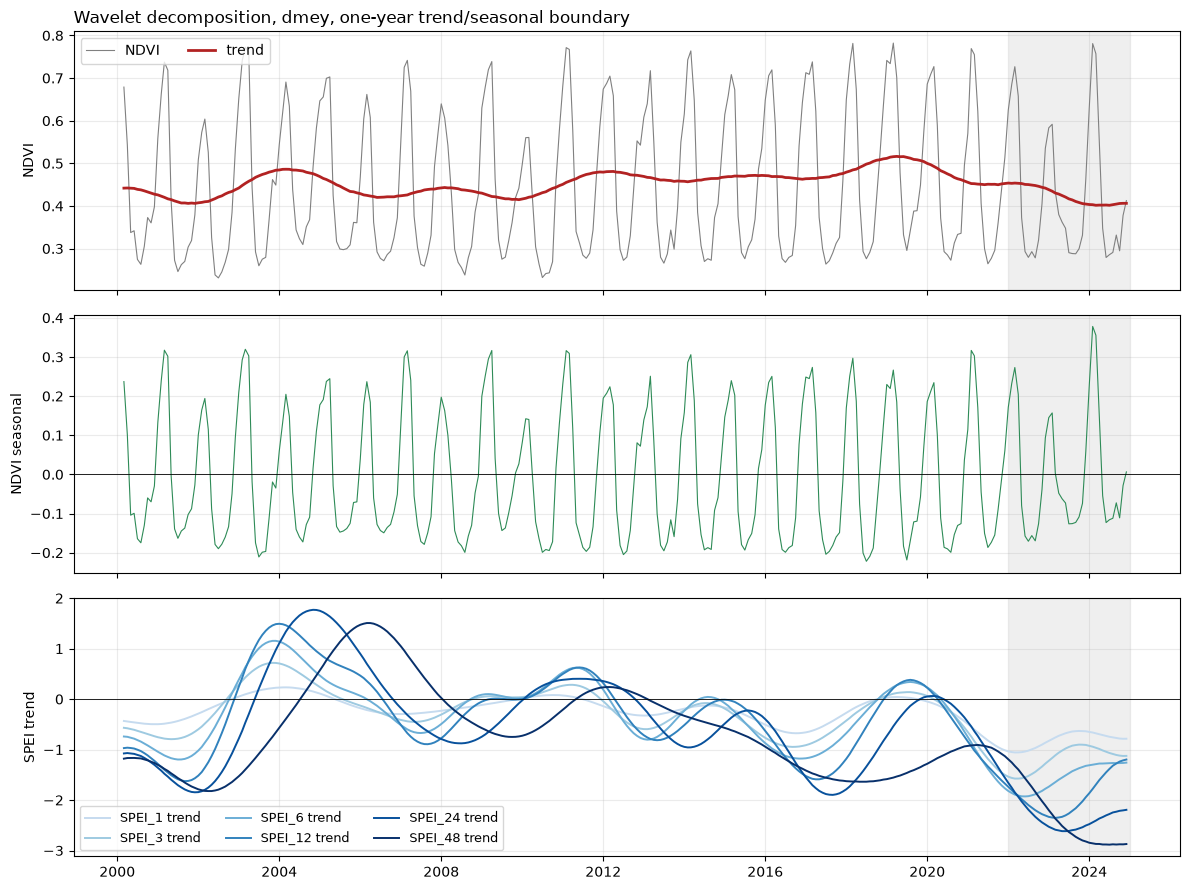

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
d = decomp.index

axes[0].plot(d, decomp["NDVI"], color="grey", lw=0.8, label="NDVI")
axes[0].plot(d, decomp["NDVI_T"], color="firebrick", lw=2, label="trend")
axes[0].set_ylabel("NDVI")
axes[0].legend(loc="upper left", ncol=2)

axes[1].plot(d, decomp["NDVI_S"], color="seagreen", lw=0.8)
axes[1].axhline(0, color="black", lw=0.6)
axes[1].set_ylabel("NDVI seasonal")

for col, shade in zip(SPEI_COLS, ["#c6dbef", "#9ecae1", "#6baed6", "#3182bd",
                                  "#08519c", "#08306b"]):
    axes[2].plot(d, decomp[f"{col}_T"], lw=1.4, color=shade, label=f"{col} trend")
axes[2].axhline(0, color="black", lw=0.6)
axes[2].set_ylabel("SPEI trend")
axes[2].legend(loc="lower left", ncol=3, fontsize=9)

for ax in axes:
    ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"),
               color="grey", alpha=0.12, zorder=0)
    ax.grid(alpha=0.25)

axes[0].set_title("Wavelet decomposition, dmey, one-year trend/seasonal boundary",
                  loc="left")
fig.tight_layout()
fig.savefig("../figures/02_decomposition.png", dpi=150, bbox_inches="tight")
plt.show()

## Look-ahead

The wavelet filter is two-sided, so the trend at month *t* uses later months. A model given
these components therefore sees part of the future, and its accuracy is overstated: the
problem is documented for wavelet and singular-spectrum hybrids in hydrology (Du et al.,
2017; Quilty and Adamowski, 2018). A causal trend, recomputed with data up to each point
only, measures the effect here.

In [6]:
def causal_trend(series, level, burn_in):
    """Trend at each t recomputed from observations up to t only."""
    out = np.full(len(series), np.nan)
    for t in range(burn_in, len(series) + 1):
        trend, _, _ = decompose(series.iloc[:t], level)
        out[t - 1] = trend.iloc[-1]
    return pd.Series(out, index=series.index)


BURN_IN_YEARS = 8
PER_YEAR = {"NDVI": 365.25 / 16, "LST": 365.25 / 8, "SPEI": 12}

for name, series in [("NDVI", ndvi16), ("LST", lst8)]:
    burn = int(BURN_IN_YEARS * PER_YEAR[name])
    decomp[f"{name}_Tc"] = (causal_trend(series, LEVELS[name], burn)
                            .resample("MS").mean())

for col in SPEI_COLS:
    decomp[f"{col}_Tc"] = causal_trend(master[col], LEVELS["SPEI"],
                                       int(BURN_IN_YEARS * PER_YEAR["SPEI"]))

print(f"{'series':9s} {'lag-1 (2-sided)':>16s} {'lag-1 (causal)':>15s} "
      f"{'persist R2 2-sided':>19s} {'persist R2 causal':>18s} {'corr':>7s}")
for col in ALL_SERIES:
    a, b = decomp[f"{col}_T"], decomp[f"{col}_Tc"]
    m = b.notna()
    a, b = a[m], b[m]
    print(f"{col:9s} {a.autocorr(1):16.4f} {b.autocorr(1):15.4f} "
          f"{r2_score(a[1:], a[:-1]):19.4f} {r2_score(b[1:], b[:-1]):18.4f} "
          f"{a.corr(b):7.3f}")

series     lag-1 (2-sided)  lag-1 (causal)  persist R2 2-sided  persist R2 causal    corr
NDVI                0.9973          0.9080              0.9946             0.8165   0.498
LST                 0.9883          0.8775              0.9767             0.7541   0.167
SPEI_1              0.9974          0.9395              0.9947             0.8795   0.784
SPEI_3              0.9971          0.9743              0.9942             0.9486   0.806
SPEI_6              0.9970          0.9859              0.9940             0.9718   0.829
SPEI_12             0.9971          0.9903              0.9943             0.9806   0.867
SPEI_24             0.9979          0.9961              0.9956             0.9921   0.970
SPEI_48             0.9992          0.9974              0.9980             0.9944   0.974


The causal wavelet trend oscillates with the annual cycle: at the right edge the filter
has no future to average over, and the mirrored extension folds the season into the trend.
The artefact appears under every padding rule tried. Quilty and Adamowski (2018) show that
only transforms whose coefficients do not depend on future values, with boundary
coefficients removed, are valid for forecasting; building that variant is left for future
work. A trailing 12-month mean is used as the causal reference instead: it averages over
exactly one year, so it cannot carry the annual cycle.

In [7]:
def causal_last(x, level, right_pad):
    """Trend value at the final point of x, under a given right-edge rule."""
    n = len(x)
    p = int(0.5 * n)
    right = {"mirror": x[-p:][::-1],
             "constant": np.full(p, x[-1]),
             "none": np.empty(0)}[right_pad]
    xp = np.concatenate([x[:p][::-1], x, right])
    return pywt.mra(xp, WAVELET, level=level,
                    transform="dwt", mode="symmetric")[0][p + n - 1]


x = ndvi16.to_numpy(float)
burn = int(BURN_IN_YEARS * PER_YEAR["NDVI"])

variants = {"wavelet, two-sided": decomp["NDVI_T"]}
for rule in ("mirror", "constant", "none"):
    out = np.full(len(x), np.nan)
    for t in range(burn, len(x) + 1):
        out[t - 1] = causal_last(x[:t], LEVELS["NDVI"], rule)
    variants[f"causal wavelet, {rule} pad"] = (
        pd.Series(out, index=ndvi16.index).resample("MS").mean())

for w in (12, 24):
    variants[f"trailing {w}-month mean"] = decomp["NDVI"].rolling(w).mean()

print(f"{'estimator':30s} {'sd':>7s} {'annual leak':>12s} {'lag-1':>7s} "
      f"{'persist R2':>11s} {'corr w/ 2-sided':>16s}")
for name, c in variants.items():
    k = c.notna()
    amp = (c[k].groupby(c[k].index.month).mean()
                .pipe(lambda v: v.max() - v.min()))
    print(f"{name:30s} {c.std():7.4f} {amp:12.4f} {c[k].autocorr(1):7.4f} "
          f"{r2_score(c[k][1:], c[k][:-1]):11.4f} "
          f"{decomp['NDVI_T'][k].corr(c[k]):16.3f}")

estimator                           sd  annual leak   lag-1  persist R2  corr w/ 2-sided
wavelet, two-sided              0.0280       0.0018  0.9968      0.9935            1.000
causal wavelet, mirror pad      0.0516       0.1097  0.9080      0.8165            0.498
causal wavelet, constant pad    0.0912       0.2270  0.8350      0.6692            0.270
causal wavelet, none pad        0.0478       0.1011  0.8999      0.8003            0.462
trailing 12-month mean          0.0325       0.0007  0.9742      0.9483            0.706
trailing 24-month mean          0.0243       0.0022  0.9915      0.9830            0.674


**Causal components.** `_Tm` is the trailing 12-month mean, the trend estimate of classical
decomposition (Hyndman and Athanasopoulos, 2021, ch. 3), but one-sided; `_Sm` is the series
minus `_Tm`, so `_Tm + _Sm` reproduces the series exactly, as for the wavelet. Both use only
the current and earlier months. Notebook 03 derives predictors for them and notebook 09
compares the two decompositions as forecasting tools. `_Tc`, the causal wavelet trend, is
kept for reference only.

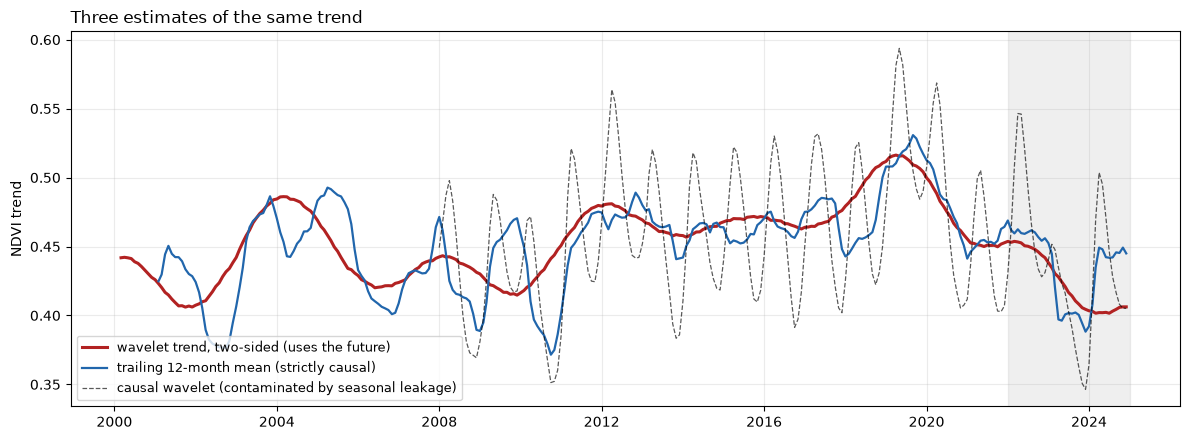

In [8]:
for col in ALL_SERIES:
    decomp[f"{col}_Tm"] = decomp[col].rolling(12).mean()
    decomp[f"{col}_Sm"] = decomp[col] - decomp[f"{col}_Tm"]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(decomp.index, decomp["NDVI_T"], color="firebrick", lw=2.2,
        label="wavelet trend, two-sided (uses the future)")
ax.plot(decomp.index, decomp["NDVI_Tm"], color="#2166ac", lw=1.6,
        label="trailing 12-month mean (strictly causal)")
ax.plot(decomp.index, decomp["NDVI_Tc"], color="black", lw=0.9, ls="--",
        alpha=0.65, label="causal wavelet (contaminated by seasonal leakage)")
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"),
           color="grey", alpha=0.12, zorder=0)
ax.set_ylabel("NDVI trend")
ax.grid(alpha=0.25)
ax.legend(loc="lower left", fontsize=9)
ax.set_title("Three estimates of the same trend", loc="left")
fig.tight_layout()
fig.savefig("../figures/02_causal_trend.png", dpi=150, bbox_inches="tight")
plt.show()

## Composite timing

MOD13Q1 composites are dated by the first day of their 16-day window, and each pixel's
value comes from one day inside that window, the best of the period by the
maximum-value-composite rule (Holben, 1986; Huete et al., 2002). A composite starting late
in a month therefore partly observes the next month, and the monthly mean of month *t − 1*,
the most recent predictor of a forecast for month *t*, can include a few days of month *t*.
The same holds for 8-day LST. This measures how much.

In [9]:
def spill(dates, days):
    # days of each composite window that fall after the end of its starting month
    dates = pd.Series(dates)
    end = dates + pd.Timedelta(days=days - 1)
    return (end - (dates + pd.offsets.MonthEnd(0))).dt.days.clip(lower=0)


for name, series, days in [("NDVI", ndvi16, 16), ("LST", lst8, 8)]:
    s = spill(series.index, days)
    month = pd.Series(series.index).dt.to_period("M")
    share = s.groupby(month).sum() / (days * s.groupby(month).size())
    print(f"{name}: {(s > 0).mean():.0%} of composites extend into the next month, "
          f"by {s[s > 0].mean():.1f} days on average (max {s.max()}); "
          f"{share.mean():.1%} of a month's observation window lies in the next month")

NDVI: 49% of composites extend into the next month, by 7.7 days on average (max 15); 22.7% of a month's observation window lies in the next month
LST: 22% of composites extend into the next month, by 3.7 days on average (max 7); 10.0% of a month's observation window lies in the next month


## Limitations

1. **Look-ahead of the two-sided filter.** Measured above. Notebooks 04–08 use the wavelet
   components as the framework does, so their branch results describe the components, not
   a forecast that could be issued in real time. Notebook 09 adds the causal decomposition
   and compares the two.
2. **No valid causal wavelet.** The boundary-corrected transform of Quilty and Adamowski
   (2018) was not implemented; the trailing 12-month mean replaces it. It is a cruder
   low-pass filter: it lags the true trend by about half a year and lets some sub-annual
   variability through.
3. **Composite timing.** Measured above: a small part of the month-*t − 1* predictor can
   come from month *t*. Notebook 09 repeats its comparison with each composite assigned to
   the month its window ends, which removes the overlap; the ranking of forecasts holds.
   Notebooks 04–08 keep the start-date assignment, so their absolute accuracies are slightly
   optimistic. Assigning each pixel to its acquisition day, from the per-pixel `DayOfYear`
   band of MOD13Q1, would be more exact still.
4. **Gap filling.** 18 of 571 NDVI composites (3%) and 8 of 1141 LST composites are
   linearly interpolated before the transform.
5. **Scale mismatch.** NDVI averages about ten 250 m pixels inside the orchard; LST covers
   0.64 of one 1 km pixel, and SPEI one 0.5° cell (about 50 km). The climate predictors
   describe the orchard's surroundings, not the orchard itself.
6. **One wavelet, one boundary.** Other wavelets or a different cut would move the split
   slightly; they were not tested here.

## Saving

In [10]:
decomp.to_csv("../data/processed/orchard_decomposed.csv")

print(decomp.shape)
print(f"\nnulls by suffix:")
for suffix in ("", "_T", "_S", "_Tc", "_Tm", "_Sm"):
    cols = [f"{c}{suffix}" for c in ALL_SERIES]
    print(f"  {suffix or '(series)':10s} {decomp[cols].isna().sum().sum():4d}  "
          f"first valid {decomp[cols].dropna().index[0].date()}")

(298, 50)

nulls by suffix:
  (series)      0  first valid 2000-03-01
  _T            0  first valid 2000-03-01
  _S            0  first valid 2000-03-01
  _Tc         759  first valid 2008-02-01
  _Tm          88  first valid 2001-02-01
  _Sm          88  first valid 2001-02-01


## References

- Ben Abbes, A., Bounouh, O., Farah, I. R., de Jong, R. & Martínez, B. (2018). Comparative study of three satellite image time-series decomposition methods for vegetation change detection. European Journal of Remote Sensing, 51(1), 607–615. https://doi.org/10.1080/22797254.2018.1465360
- Du, K., Zhao, Y. & Lei, J. (2017). The incorrect usage of singular spectral analysis and discrete wavelet transform in hybrid models to predict hydrological time series. Journal of Hydrology, 552, 44–51. https://doi.org/10.1016/j.jhydrol.2017.06.019
- Holben, B. N. (1986). Characteristics of maximum-value composite images from temporal AVHRR data. International Journal of Remote Sensing, 7(11), 1417–1434.
- Huete, A., Didan, K., Miura, T., Rodriguez, E. P., Gao, X. & Ferreira, L. G. (2002). Overview of the radiometric and biophysical performance of the MODIS vegetation indices. Remote Sensing of Environment, 83(1–2), 195–213.
- Hyndman, R. J. & Athanasopoulos, G. (2021). Forecasting: Principles and Practice (3rd ed.). OTexts, Melbourne. https://otexts.com/fpp3/
- Lee, G. R., Gommers, R., Waselewski, F., Wohlfahrt, K. & O'Leary, A. (2019). PyWavelets: A Python package for wavelet analysis. Journal of Open Source Software, 4(36), 1237.
- Mallat, S. G. (1989). A theory for multiresolution signal decomposition: the wavelet representation. IEEE Transactions on Pattern Analysis and Machine Intelligence, 11(7), 674–693.
- Martínez, B. & Gilabert, M. A. (2009). Vegetation dynamics from NDVI time series analysis using the wavelet transform. Remote Sensing of Environment, 113(9), 1823–1842.
- Percival, D. B. & Walden, A. T. (2000). Wavelet Methods for Time Series Analysis. Cambridge University Press.
- Quilty, J. & Adamowski, J. (2018). Addressing the incorrect usage of wavelet-based hydrological and water resources forecasting models for real-world applications with best practices and a new forecasting framework. Journal of Hydrology, 563, 336–353. https://doi.org/10.1016/j.jhydrol.2018.05.003